In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.incident_simulation import simulate_incidents

from src.model_validation_parameter_uncertainty import (
    run_frequency_parameter_uncertainty,
    summarize_parameter_uncertainty,
)

print("Imports successful.")


Imports successful.


In [2]:

#Estimate baseline incident-loss expectation
#Rather than hardcoding the incident loss from an earlier run, we'll estimate it using our existing simulation.

baseline_incidents = simulate_incidents(
    n_incidents=100_000,
    seed=20261108,
)

expected_incident_loss = baseline_incidents[
    "total_incident_loss_usd"
].mean()

print(
    "Estimated expected loss per successful incident:",
    f"${expected_incident_loss:,.2f}"
)


Estimated expected loss per successful incident: $1,230,364.99


In [3]:
#Sample uncertain frequency parameters

parameter_draws = run_frequency_parameter_uncertainty(
    expected_incident_loss_usd=expected_incident_loss,
    n_draws=20_000,
    seed=20261107,
)

display(parameter_draws.head())

print("\nParameter distribution summaries:")

display(
    parameter_draws[
        [
            "campaign_rate",
            "mean_success_probability",
            "expected_annual_lef",
        ]
    ].describe(
        percentiles=[0.05, 0.50, 0.95]
    )
)


,draw,campaign_rate,mean_success_probability,expected_annual_lef,expected_annual_loss_usd
0,1,3.362008,0.091721,0.308365,379402.039724
1,2,3.156828,0.054572,0.172276,211962.169072
2,3,2.710019,0.065665,0.177953,218946.851904
3,4,3.865487,0.103346,0.399482,491509.236542
4,5,2.041261,0.031092,0.063467,78087.316001



Parameter distribution summaries:


,campaign_rate,mean_success_probability,expected_annual_lef
count,20000.000000,20000.000000,20000.000000
mean,2.996279,0.074450,0.223072
std,0.992208,0.037235,0.138548
min,0.410786,0.004076,0.006715
5%,1.586430,0.024719,0.059668
50%,2.887120,0.068335,0.193014
95%,4.811658,0.145274,0.490370
max,8.857674,0.353215,1.342460


In [4]:
#Summarize uncertainty in AAL


summary = summarize_parameter_uncertainty(
    parameter_draws,
    expected_incident_loss,
)

summary_df = pd.DataFrame([
    {"Metric": key, "Value": value}
    for key, value in summary.items()
])

display(
    summary_df.style.format({
        "Value": "${:,.0f}",
    })
)


,Metric,Value
0,baseline_aal_usd,"$274,544"
1,mean_aal_usd,"$274,460"
2,median_aal_usd,"$237,477"
3,aal_p05_usd,"$73,413"
4,aal_p95_usd,"$603,334"
5,aal_p025_usd,"$56,337"
6,aal_p975_usd,"$706,473"
7,aal_sd_usd,"$170,464"


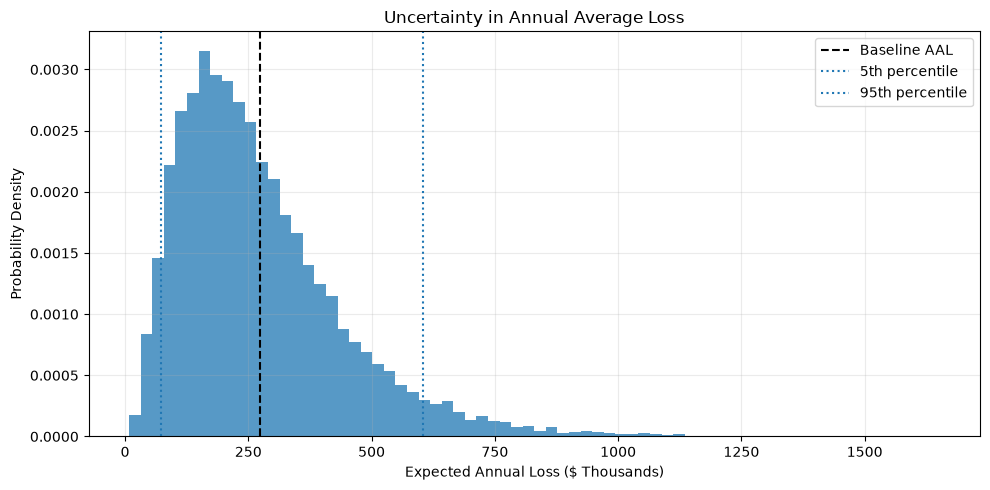

In [5]:
#Visualize the AAL uncertainty distribution


aal = (
    parameter_draws["expected_annual_loss_usd"]
    / 1_000
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    aal,
    bins=70,
    density=True,
    alpha=0.75,
)

ax.axvline(
    summary["baseline_aal_usd"] / 1_000,
    linestyle="--",
    color="black",
    label="Baseline AAL",
)

ax.axvline(
    summary["aal_p05_usd"] / 1_000,
    linestyle=":",
    label="5th percentile",
)

ax.axvline(
    summary["aal_p95_usd"] / 1_000,
    linestyle=":",
    label="95th percentile",
)

ax.set_title(
    "Uncertainty in Annual Average Loss"
)
ax.set_xlabel("Expected Annual Loss ($ Thousands)")
ax.set_ylabel("Probability Density")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [6]:
#How much does each frequency parameter contribute?


baseline_lambda = 3.0
baseline_p = 0.36 / (0.36 + 4.48)

lambda_draws = parameter_draws[
    "campaign_rate"
].to_numpy()

p_draws = parameter_draws[
    "mean_success_probability"
].to_numpy()

aal_campaign_only = (
    lambda_draws
    * baseline_p
    * expected_incident_loss
)

aal_success_only = (
    baseline_lambda
    * p_draws
    * expected_incident_loss
)

aal_both = (
    lambda_draws
    * p_draws
    * expected_incident_loss
)

comparison = pd.DataFrame([
    {
        "Scenario": "Campaign rate uncertain",
        "AAL SD": np.std(aal_campaign_only, ddof=1),
    },
    {
        "Scenario": "Success probability uncertain",
        "AAL SD": np.std(aal_success_only, ddof=1),
    },
    {
        "Scenario": "Both uncertain",
        "AAL SD": np.std(aal_both, ddof=1),
    },
])

display(
    comparison.style.format({
        "AAL SD": "${:,.0f}",
    })
)


,Scenario,AAL SD
0,Campaign rate uncertain,"$90,802"
1,Success probability uncertain,"$137,438"
2,Both uncertain,"$170,464"


In [7]:
#Step 7D-2 — Loss Magnitude Parameter Uncertainty
#First, inspect the exact configuration structure
from pprint import pprint

from config.model_config import get_config

cfg = get_config()

print("=" * 60)
print("REPUTATION CONFIGURATION")
print("=" * 60)

pprint(cfg["reputation"], depth=8)

print("\n" + "=" * 60)
print("SENSITIVITY CONFIGURATION")
print("=" * 60)

pprint(cfg["sensitivity"], depth=8)

print("\n" + "=" * 60)
print("AFFECTED CHURN PROBABILITY")
print("=" * 60)

pprint(cfg["probabilities"]["affected_churn"])

print("\n" + "=" * 60)
print("EXISTING MAGNITUDE CONFIG FUNCTION")
print("=" * 60)

import inspect
from src.sensitivity_analysis_loss_magnitude import (
    make_magnitude_config,
)

print(inspect.getsource(make_magnitude_config))


REPUTATION CONFIGURATION
{'affected_count_rounding': 'round_to_nearest_integer_and_clip_0_to_customer_total',
 'affected_customers': {'family': 'pert',
                        'max': 3000,
                        'min': 300,
                        'mode': 1500,
                        'shape_lambda': 4.0},
 'churn': {'affected': {'distribution': 'binomial',
                        'probability_model': 'affected_churn',
                        'trials': 'affected_customers'},
           'unaffected': {'distribution': 'binomial',
                          'probability_model': 'unaffected_churn',
                          'trials': 'unaffected_customers'}},
 'loss_per_churned_customer_usd': 210000,
 'loss_per_lost_deal_usd': 210000,
 'lost_deals': {'distribution': 'binomial',
                'probability_model': 'lost_deal',
                'trials': 'otherwise_won_opportunities'},
 'note': 'No additional multi-year customer lifetime value or double counting '
         'of lost deals and